
# Voice Recognition and Speaker Verification
## Multimodal Data Preprocessing — Formative 2

**Project:** User Identity and Product Recommendation System  
**Task:** Audio Data Collection, Preprocessing and Voiceprint Verification  
**Student:** Alain Christian Mugenga  
**Group Members:** Alain, Bode, Elyse and Hycient

---

## 1. Introduction

## 1.1 Background

Voice recognition is an important component of the multimodal authentication system developed in this project. The system uses voiceprint verification to determine whether a person attempting to confirm a product prediction is an authorized user.

This notebook focuses on the collection, preprocessing, visualization, augmentation and feature extraction of audio recordings from the four group members. It also implements and evaluates a machine learning model for speaker verification.

The audio recordings contain two predefined phrases:

- "Yes, approve"
- "Confirm transaction"

The objective is to extract meaningful acoustic characteristics from these recordings and use them to distinguish between authorized speakers and unauthorized individuals.

## 1.2. Project Objectives

The main objectives of this notebook are:

1. Load and inspect the audio recordings of all four group members.
2. Visualize each recording using waveforms and spectrograms.
3. Apply at least two audio augmentation techniques to each original recording.
4. Extract relevant audio features, including Mel-Frequency Cepstral Coefficients (MFCCs), spectral roll-off and energy.
5. Save the extracted features into `audio_features.csv`.
6. Develop a voiceprint verification model.
7. Evaluate the model using appropriate performance metrics, including accuracy, F1-score and loss where applicable.

## 1.3. Dataset Description

The dataset consists of eight original WAV audio recordings collected from four group members.

Each member provides two recordings, with each recording containing one of the required phrases.

| Speaker | Recording 1 | Recording 2 |
|---|---|---|
| Alain | Yes, approve | Confirm transaction |
| Bode | Yes, approve | Confirm transaction |
| Elyse | Yes, approve | Confirm transaction |
| Hycient | Yes, approve | Confirm transaction |

The recordings are stored in Google Drive to ensure persistent access and facilitate collaboration.

## 1.4. Methodology

The audio processing pipeline follows these stages:

1. Data access and verification
2. Audio loading and inspection
3. Waveform and spectrogram visualization
4. Audio augmentation
5. Acoustic feature extraction
6. Feature dataset creation
7. Voiceprint model development
8. Model evaluation

Each stage is documented and implemented using Python.



# 2. Environment Setup and Google Drive Connection

Google Drive is used to store the original audio recordings and generated project outputs. Connecting Google Drive to Google Colab allows the notebook to access the dataset whenever the drive is mounted.

The original WAV recordings will remain unchanged. Augmented recordings, visualizations, extracted features and trained models will be stored separately to maintain an organized workflow.


In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive



# 3. Audio Dataset Loading and Verification

Before preprocessing, the audio dataset must be inspected to confirm that all expected recordings are available.

The dataset contains four speakers, with two recordings per speaker. Each speaker should have one recording of "Yes, approve" and another of "Confirm transaction".

The following verification checks the presence of all eight WAV files in Google Drive. This ensures that the complete dataset is available before proceeding with audio processing.


In [2]:

from pathlib import Path

# Google Drive location
DRIVE_ROOT = Path("/content/drive/MyDrive")

# Required original recordings
expected_files = [
    "alain_yes_approve.wav",
    "alain_confirm_transaction.wav",
    "bode_yes_approve.wav",
    "bode_confirm_transaction.wav",
    "elyse_yes_approve.wav",
    "elyse_confirm_transaction.wav",
    "hycient_yes_approve.wav",
    "hycient_confirm_transaction.wav"
]

# Search Google Drive for the recordings
audio_files = {}

for filename in expected_files:
    matches = list(DRIVE_ROOT.rglob(filename))

    if matches:
        audio_files[filename] = matches[0]
        print(f"FOUND: {filename}")
    else:
        print(f"MISSING: {filename}")

print("\nTotal recordings found:", len(audio_files), "/ 8")

# Store the folder containing the recordings
if len(audio_files) == 8:
    AUDIO_DIR = next(iter(audio_files.values())).parent
    print("\nAudio folder:", AUDIO_DIR)


FOUND: alain_yes_approve.wav
FOUND: alain_confirm_transaction.wav
FOUND: bode_yes_approve.wav
FOUND: bode_confirm_transaction.wav
FOUND: elyse_yes_approve.wav
FOUND: elyse_confirm_transaction.wav
FOUND: hycient_yes_approve.wav
FOUND: hycient_confirm_transaction.wav

Total recordings found: 8 / 8

Audio folder: /content/drive/MyDrive/Multimodal-Data-Preprocessing/Voice_Recognition/Original_Audio



# 4. Audio Visualization and Inspection

Audio visualization helps us understand the characteristics and quality of the collected recordings before applying preprocessing and augmentation techniques.

Two visualization methods will be used:

**1. Waveform:** Displays how the audio signal's amplitude changes over time. It helps us inspect the duration, loudness variations and silence within each recording.

**2. Spectrogram:** Displays how the frequency content of an audio signal changes over time. It helps us observe the distribution of different frequencies and identify patterns in the speakers' voices.

Both visualizations will be generated for all eight original recordings. The recordings will also be inspected for their sampling rates, durations and signal characteristics.


In [3]:
!pip install -q librosa soundfile

import librosa
import librosa.display
import soundfile as sf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [4]:

# Store audio signals and their sample rates
audio_data = {}

for filename, filepath in audio_files.items():

    # Load audio without changing its original sample rate
    signal, sample_rate = librosa.load(
        filepath,
        sr=None,
        mono=True
    )

    # Store the recording
    audio_data[filename] = {
        "signal": signal,
        "sample_rate": sample_rate,
        "duration": len(signal) / sample_rate
    }

# Display recording information
audio_summary = []

for filename, data in audio_data.items():
    audio_summary.append({
        "Filename": filename,
        "Sample Rate (Hz)": data["sample_rate"],
        "Duration (seconds)": round(data["duration"], 2),
        "Number of Samples": len(data["signal"])
    })

audio_summary_df = pd.DataFrame(audio_summary)

display(audio_summary_df)

print("Total audio recordings loaded:", len(audio_data))


,Filename,Sample Rate (Hz),Duration (seconds),Number of Samples
0,alain_yes_approve.wav,44100,3.37,148520
1,alain_confirm_transaction.wav,44100,3.62,159800
2,bode_yes_approve.wav,44100,2.52,111132
3,bode_confirm_transaction.wav,44100,5.54,244314
4,elyse_yes_approve.wav,44100,3.88,171080
5,elyse_confirm_transaction.wav,44100,3.54,156040
6,hycient_yes_approve.wav,44100,3.15,138946
7,hycient_confirm_transaction.wav,44100,3.76,165854


Total audio recordings loaded: 8



## 4.1 Waveform and Spectrogram Visualization

The following visualizations display the time-domain and frequency-domain characteristics of each original audio recording.

For every recording:

- The waveform will show amplitude against time.
- The spectrogram will show frequency against time, with colour intensity representing signal energy.

Generating these visualizations for every speaker allows us to inspect the recordings individually and compare their acoustic characteristics before augmentation.


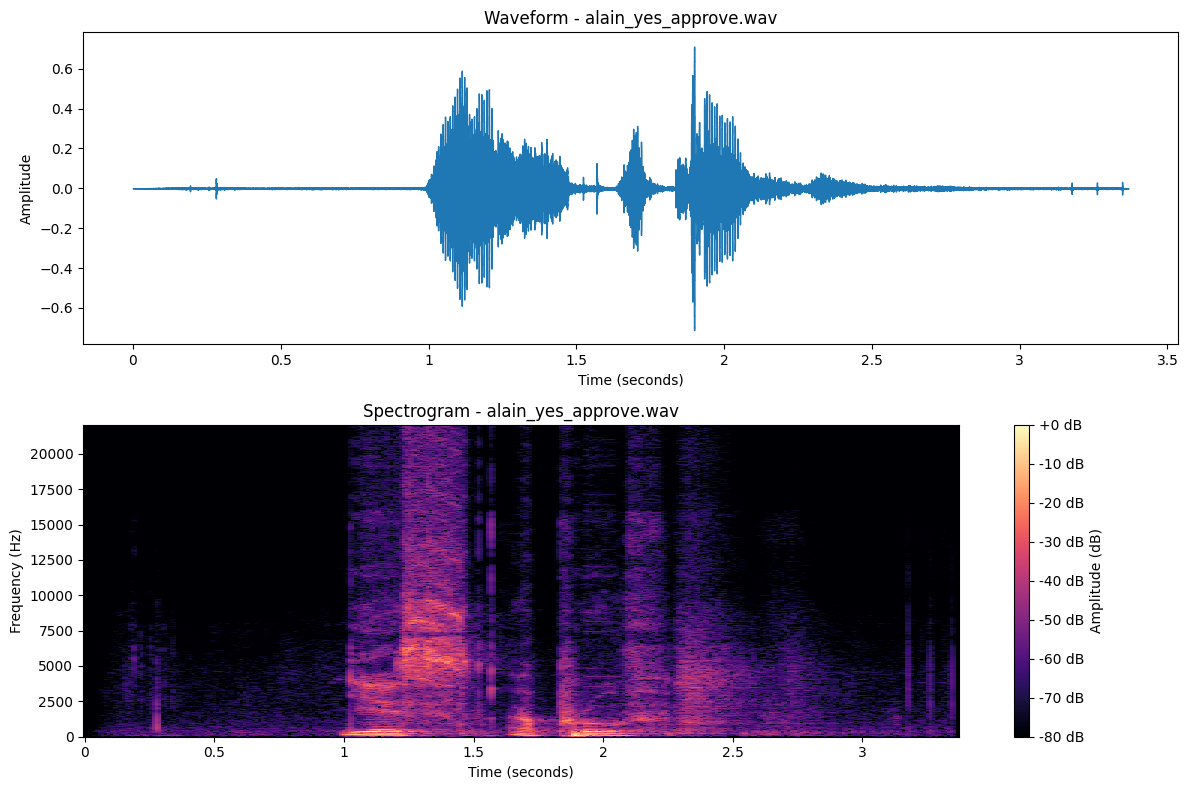

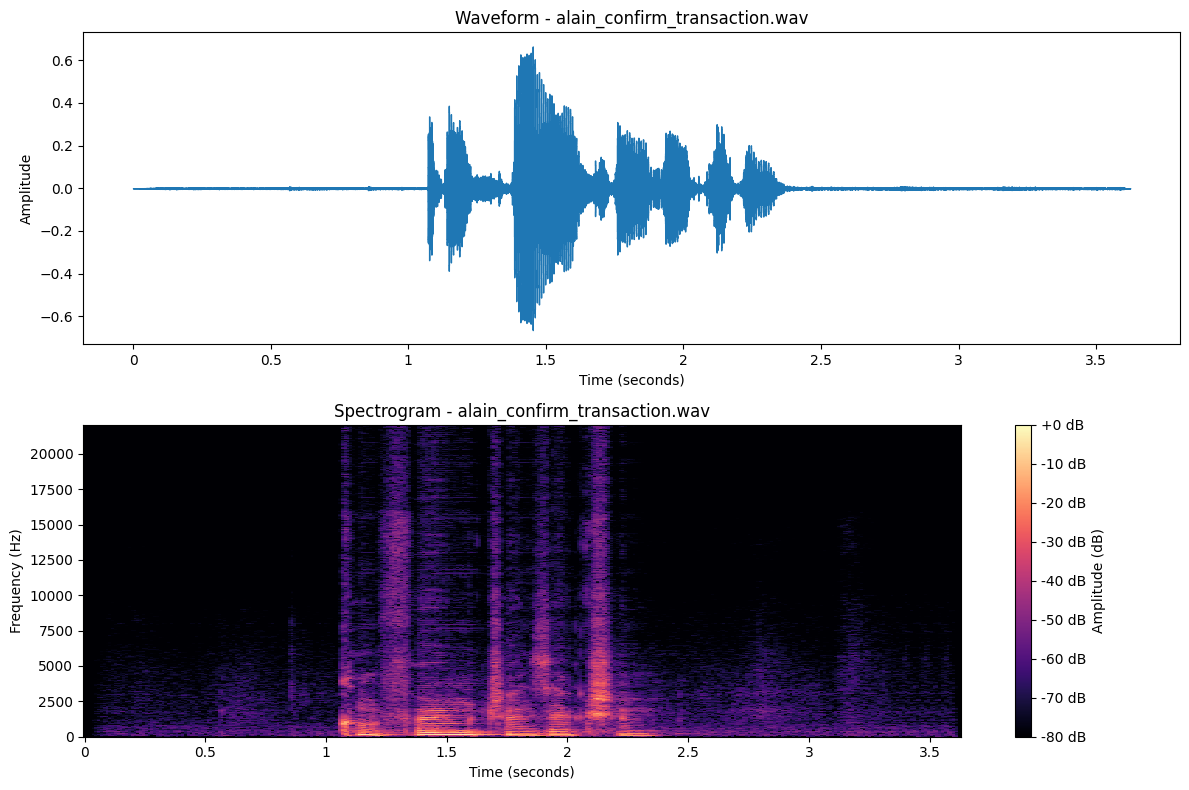

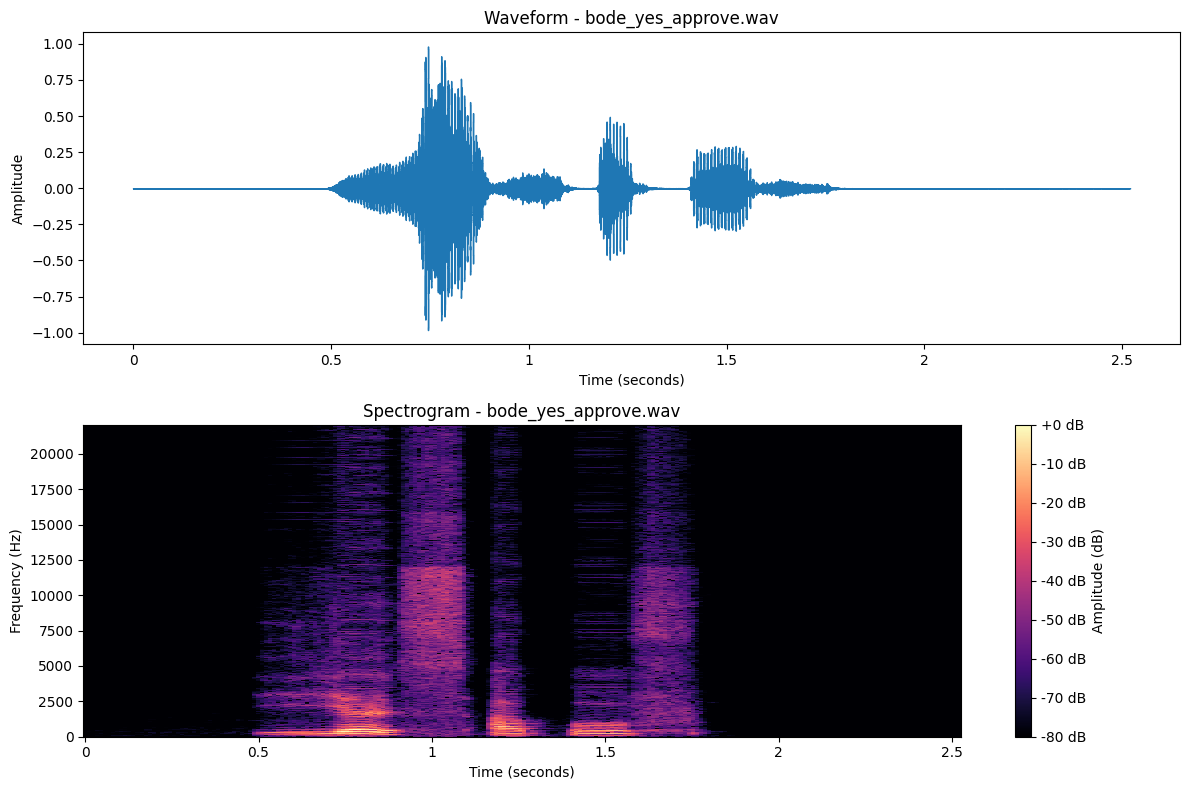

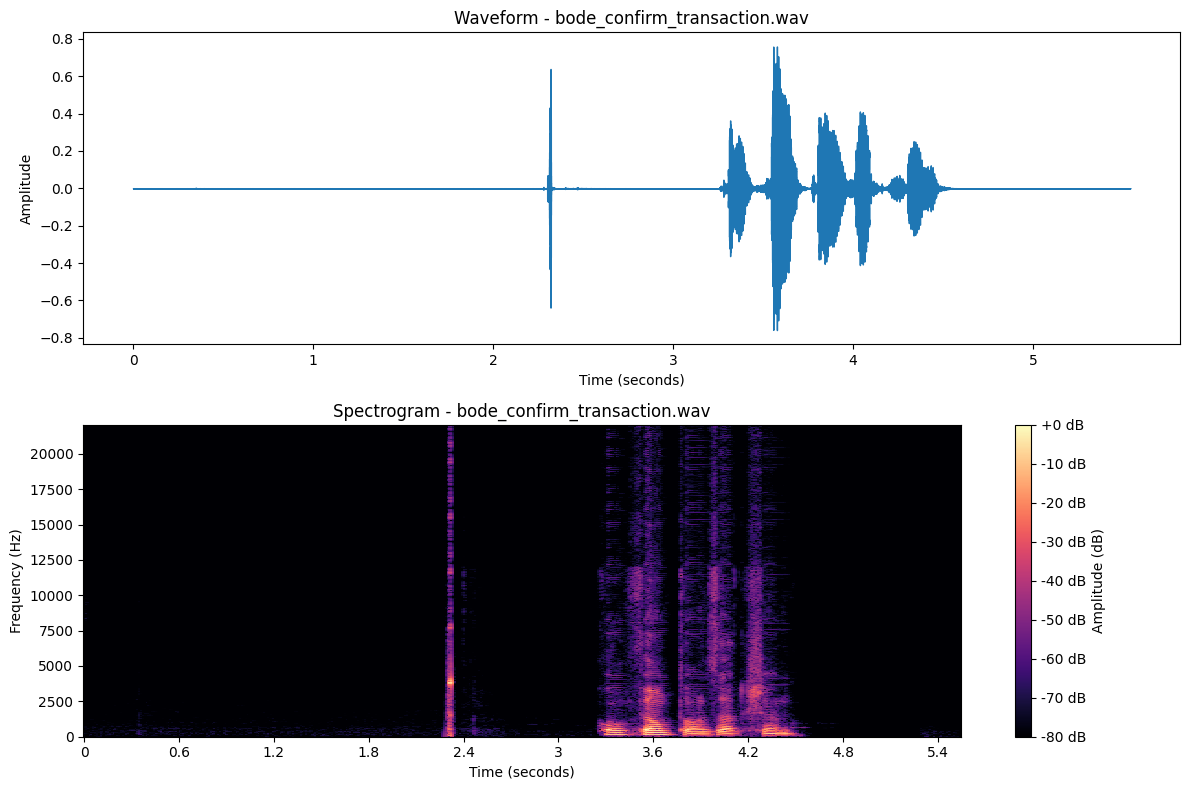

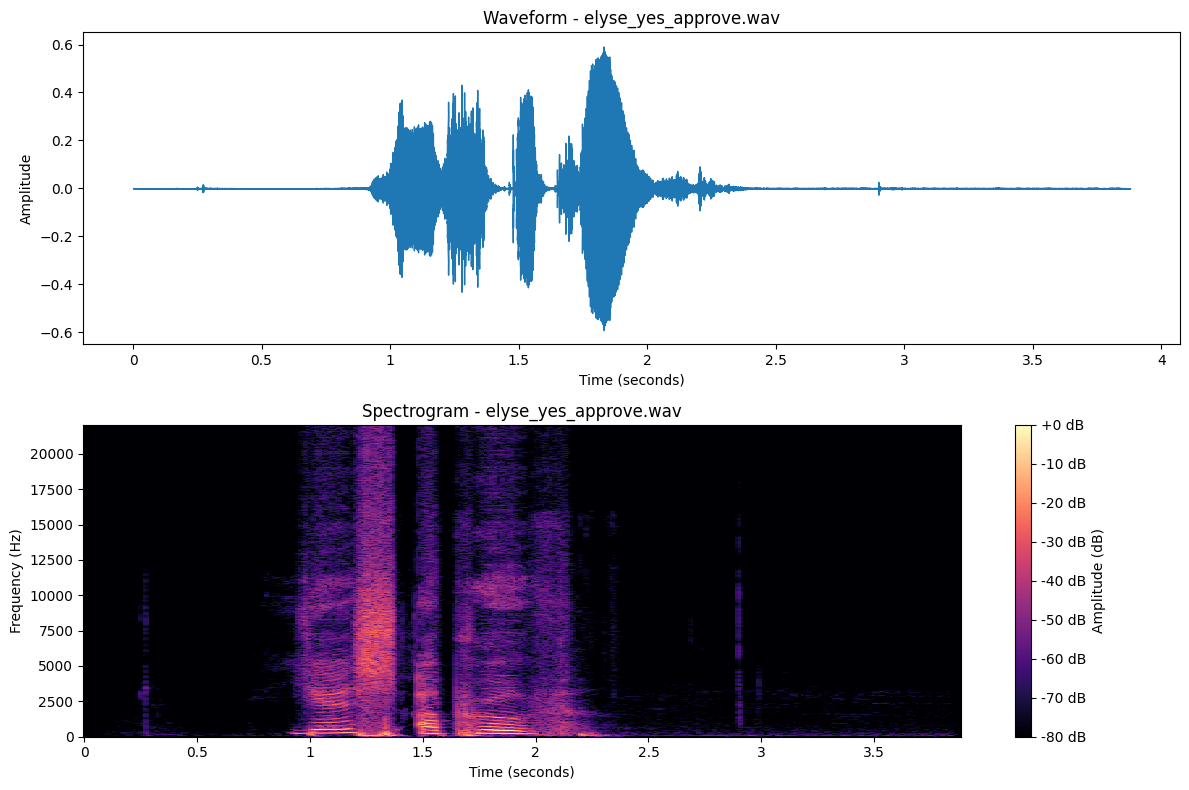

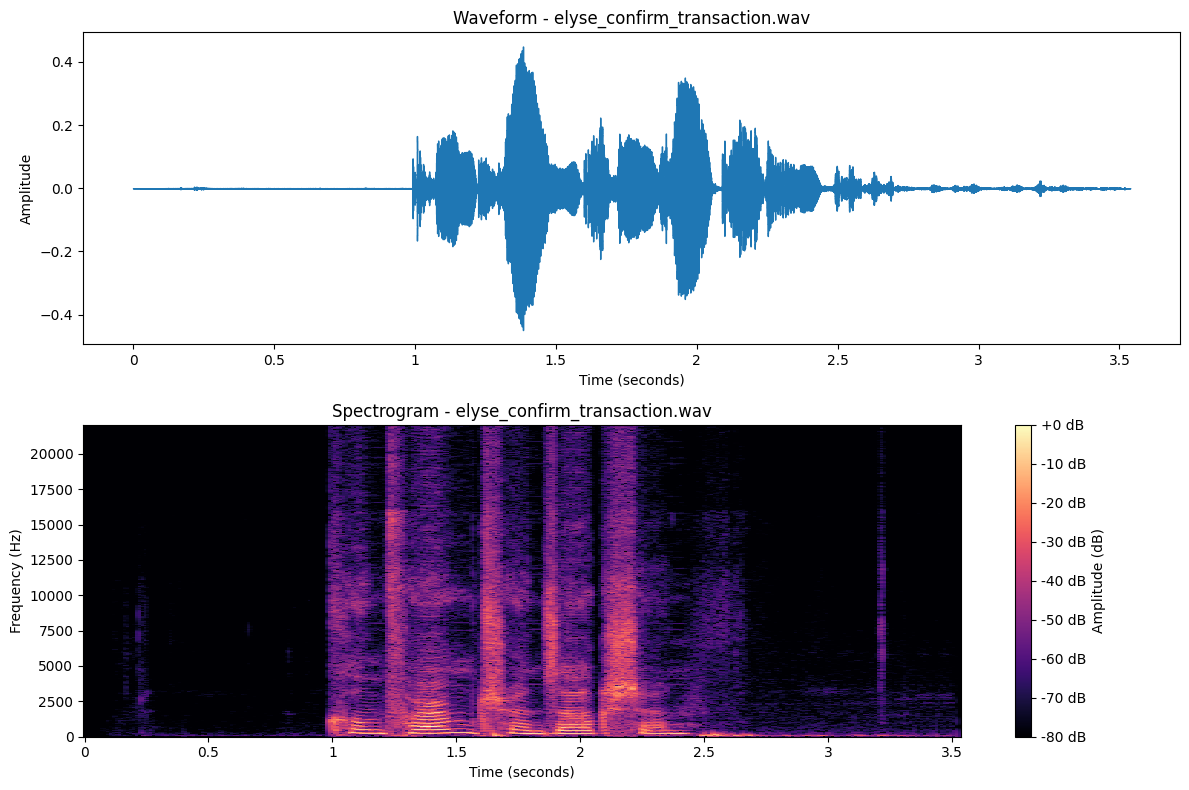

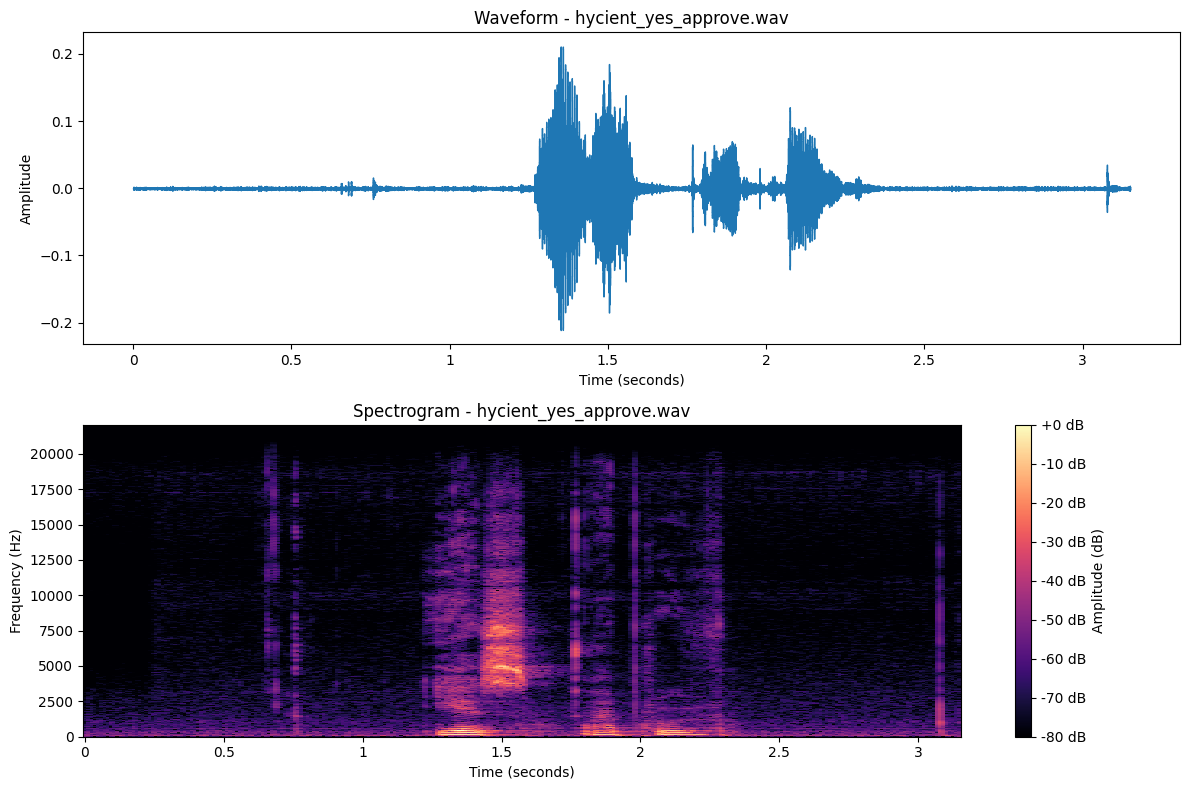

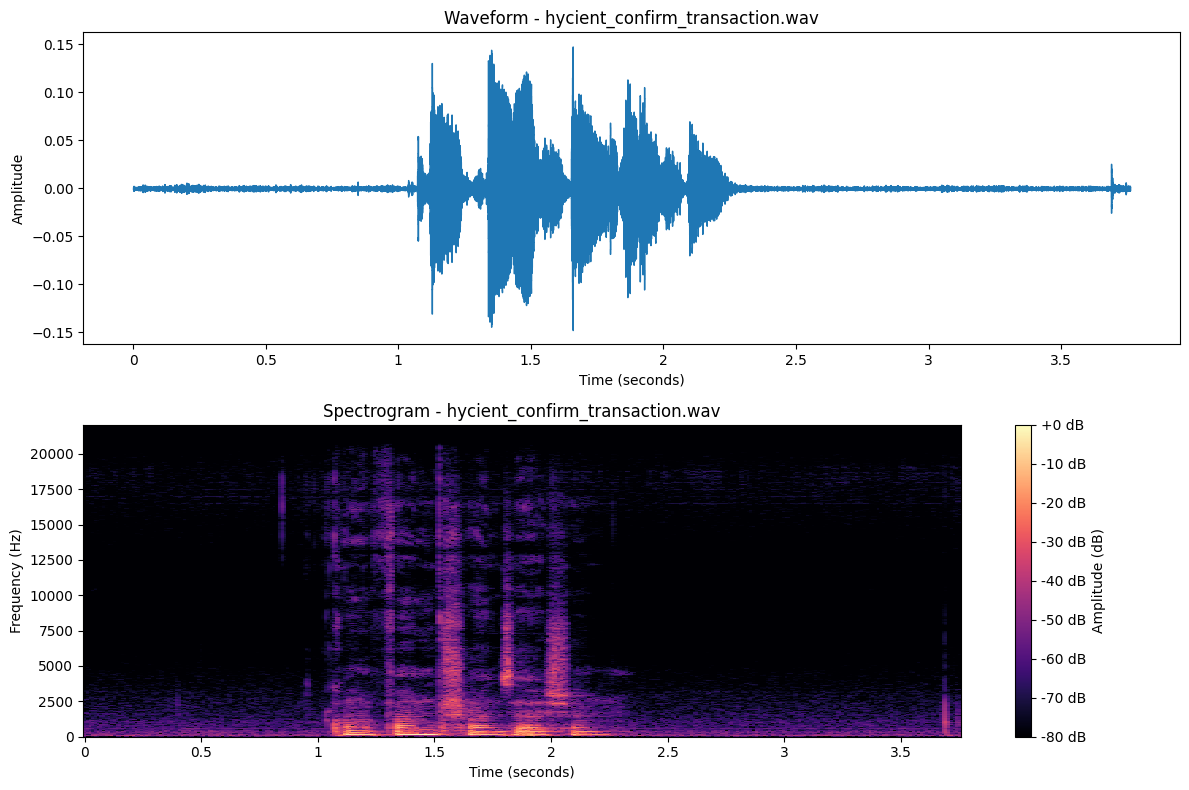

In [5]:

for filename, data in audio_data.items():

    signal = data["signal"]
    sample_rate = data["sample_rate"]

    # Create time axis
    time = np.arange(len(signal)) / sample_rate

    # Calculate spectrogram
    stft = librosa.stft(signal)
    spectrogram = librosa.amplitude_to_db(
        np.abs(stft),
        ref=np.max
    )

    fig, axes = plt.subplots(2, 1, figsize=(12, 8))

    # Waveform
    librosa.display.waveshow(
        signal,
        sr=sample_rate,
        ax=axes[0]
    )

    axes[0].set_title(f"Waveform - {filename}")
    axes[0].set_xlabel("Time (seconds)")
    axes[0].set_ylabel("Amplitude")

    # Spectrogram
    img = librosa.display.specshow(
        spectrogram,
        sr=sample_rate,
        x_axis="time",
        y_axis="hz",
        ax=axes[1],
        cmap="magma"
    )

    axes[1].set_title(f"Spectrogram - {filename}")
    axes[1].set_xlabel("Time (seconds)")
    axes[1].set_ylabel("Frequency (Hz)")

    fig.colorbar(
        img,
        ax=axes[1],
        format="%+2.0f dB",
        label="Amplitude (dB)"
    )

    plt.tight_layout()
    plt.show()



## 4.2 Visualization Analysis

The eight waveform and spectrogram plots show the following:

- **Waveforms:** All recordings contain visible speech activity, with variations in amplitude and speaking duration.
- **Silence:** Most recordings contain pauses before or after speech, which is normal in voice recordings.
- **Spectrograms:** The plots show changing frequency patterns throughout the spoken phrases, illustrating the acoustic characteristics of speech.
- **Speaker differences:** Variations in amplitude and frequency patterns can be observed across the four speakers.

All eight recordings were successfully visualized. Their sampling rate is consistent at 44,100 Hz, while their durations vary between 2.52 and 5.54 seconds.

These observations confirm that the recordings are available for further audio processing.


# 5. Audio Preprocessing

Audio preprocessing prepares the recordings for augmentation and feature extraction. This stage examines silence, audio levels and potential background noise.

The recordings will be inspected before any modifications are made. Unnecessary leading and trailing silence may be trimmed, while speech content will be preserved. Noise reduction will only be applied when noticeable background noise is identified.

All processed recordings will be saved separately, preserving the original WAV files.

In [6]:
from pathlib import Path

# Create separate output folders in Google Drive
CLEANED_DIR = AUDIO_DIR.parent / "Cleaned_Audio"
AUGMENTED_DIR = AUDIO_DIR.parent / "Augmented_Audio"
FEATURES_DIR = AUDIO_DIR.parent / "Features"
MODELS_DIR = AUDIO_DIR.parent / "Models"
RESULTS_DIR = AUDIO_DIR.parent / "Results"

for folder in [
    CLEANED_DIR,
    AUGMENTED_DIR,
    FEATURES_DIR,
    MODELS_DIR,
    RESULTS_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project folders created successfully.")

for folder in [
    CLEANED_DIR,
    AUGMENTED_DIR,
    FEATURES_DIR,
    MODELS_DIR,
    RESULTS_DIR
]:
    print(folder)

Project folders created successfully.
/content/drive/MyDrive/Multimodal-Data-Preprocessing/Voice_Recognition/Cleaned_Audio
/content/drive/MyDrive/Multimodal-Data-Preprocessing/Voice_Recognition/Augmented_Audio
/content/drive/MyDrive/Multimodal-Data-Preprocessing/Voice_Recognition/Features
/content/drive/MyDrive/Multimodal-Data-Preprocessing/Voice_Recognition/Models
/content/drive/MyDrive/Multimodal-Data-Preprocessing/Voice_Recognition/Results


## 5.2 Silence and Audio Level Inspection

Each recording is examined to estimate the amount of silence at the beginning and end, as well as its overall audio level.

The measurements help identify recordings that may benefit from trimming or further processing.

In [7]:
inspection_results = []

for filename, data in audio_data.items():

    signal = data["signal"]
    sample_rate = data["sample_rate"]

    frame_length = 2048
    hop_length = 512

    rms = librosa.feature.rms(
        y=signal,
        frame_length=frame_length,
        hop_length=hop_length
    )[0]

    threshold = max(np.max(rms) * 0.05, 1e-5)
    active_frames = np.where(rms > threshold)[0]

    if len(active_frames) > 0:

        first_active_time = (
            active_frames[0] * hop_length / sample_rate
        )

        last_active_time = (
            active_frames[-1] * hop_length / sample_rate
        )

        leading_silence = first_active_time

        trailing_silence = (
            len(signal) / sample_rate - last_active_time
        )

    else:
        leading_silence = None
        trailing_silence = None

    inspection_results.append({
        "Filename": filename,
        "Duration (seconds)": round(len(signal) / sample_rate, 2),
        "Leading Silence (seconds)": (
            round(leading_silence, 2)
            if leading_silence is not None else None
        ),
        "Trailing Silence (seconds)": (
            round(trailing_silence, 2)
            if trailing_silence is not None else None
        ),
        "Maximum RMS Energy": round(float(np.max(rms)), 4),
        "Mean RMS Energy": round(float(np.mean(rms)), 4)
    })

inspection_df = pd.DataFrame(inspection_results)

display(inspection_df)

,Filename,Duration (seconds),Leading Silence (seconds),Trailing Silence (seconds),Maximum RMS Energy,Mean RMS Energy
0,alain_yes_approve.wav,3.37,0.99,0.95,0.2423,0.0332
1,alain_confirm_transaction.wav,3.62,1.06,1.27,0.2298,0.0362
2,bode_yes_approve.wav,2.52,0.51,0.94,0.3878,0.0416
3,bode_confirm_transaction.wav,5.54,2.29,1.06,0.2395,0.0164
4,elyse_yes_approve.wav,3.88,0.93,1.62,0.2813,0.0306
5,elyse_confirm_transaction.wav,3.54,0.98,0.83,0.1616,0.0270
6,hycient_yes_approve.wav,3.15,1.25,0.05,0.0846,0.0091
7,hycient_confirm_transaction.wav,3.76,1.06,1.51,0.0782,0.0109


## 5.3 Visual Inspection of Silence Boundaries

The estimated speech boundaries are visualized for each recording to verify whether the detected silence corresponds to actual silence.

This inspection helps prevent the removal of quiet speech or important parts of the spoken phrases.

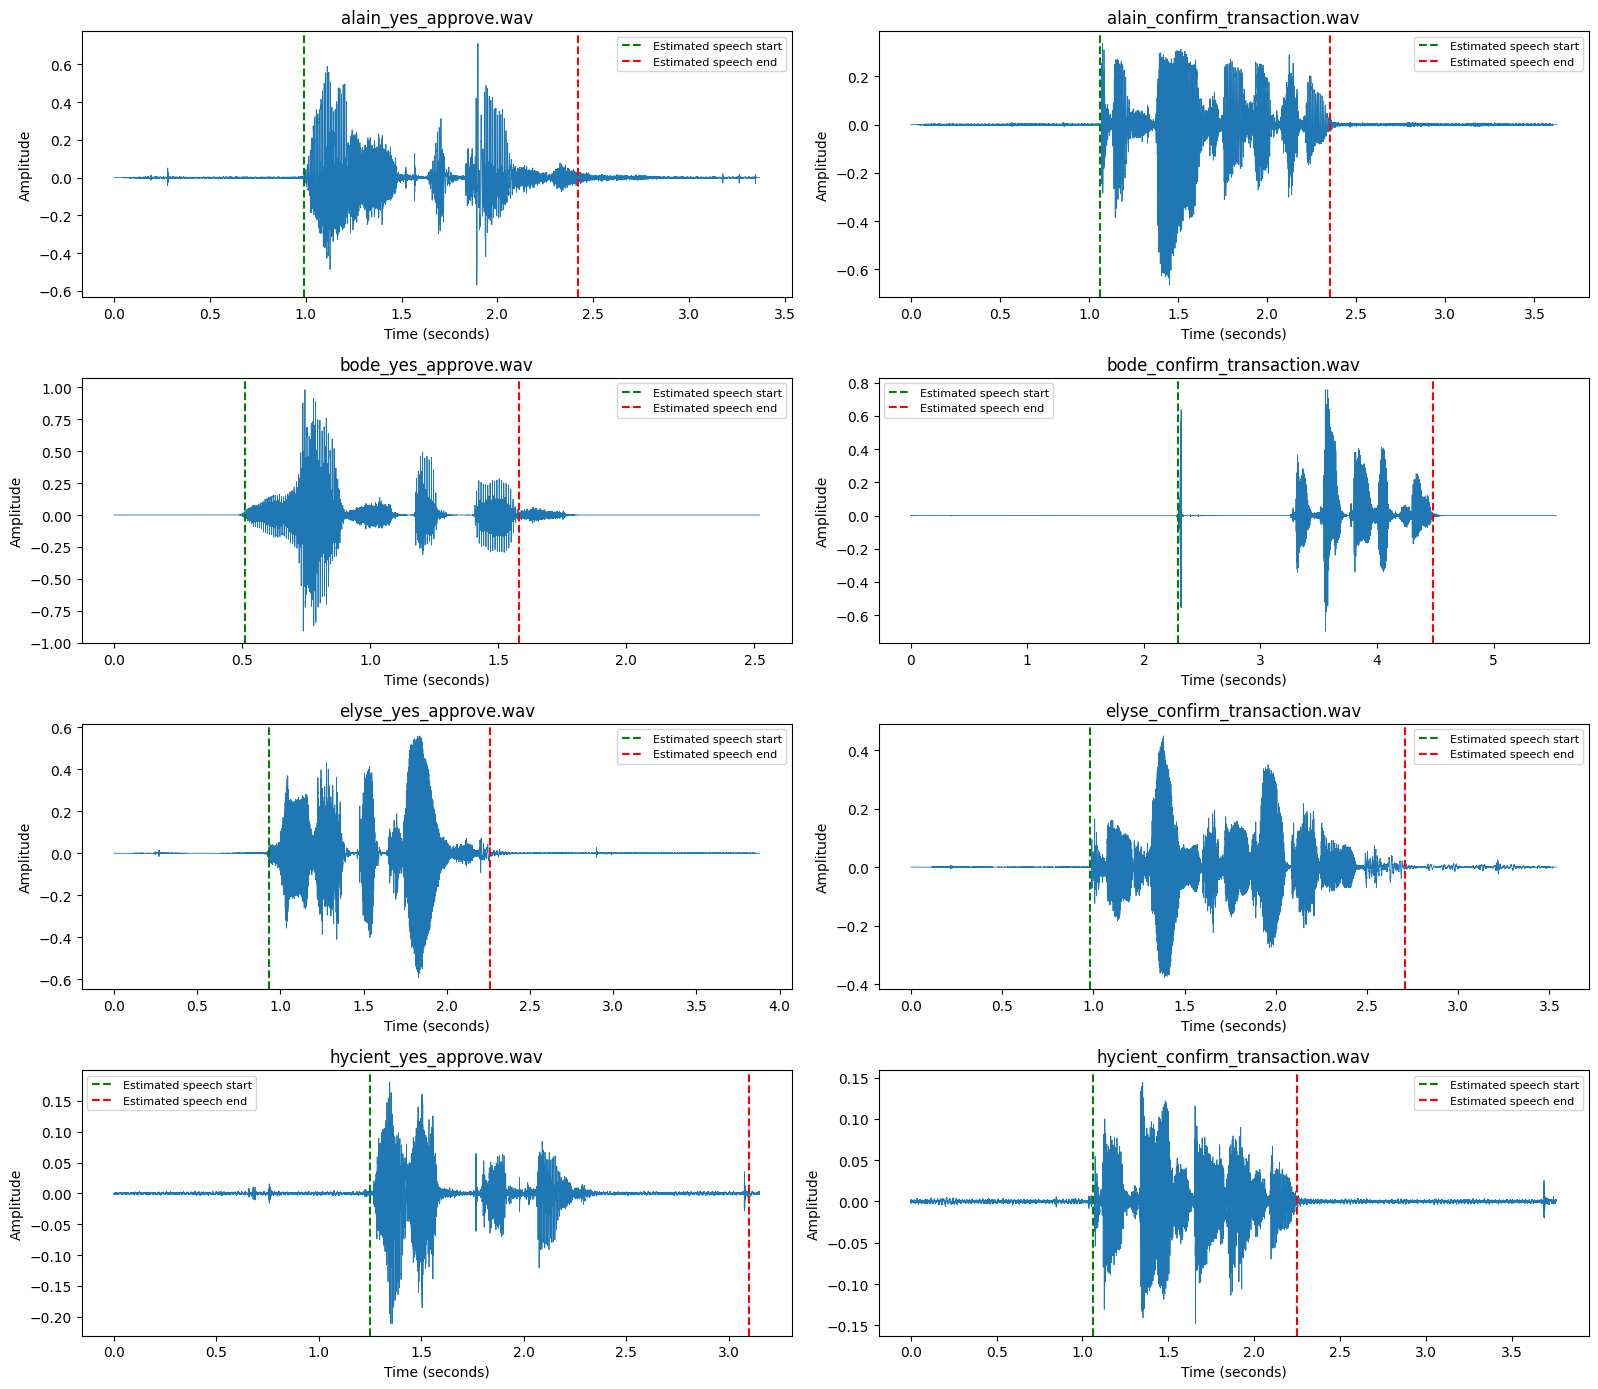

In [8]:
fig, axes = plt.subplots(4, 2, figsize=(16, 14))
axes = axes.flatten()

for i, (filename, data) in enumerate(audio_data.items()):

    signal = data["signal"]
    sample_rate = data["sample_rate"]

    time = np.arange(len(signal)) / sample_rate

    axes[i].plot(time, signal, linewidth=0.6)

    row = inspection_df[
        inspection_df["Filename"] == filename
    ].iloc[0]

    start = row["Leading Silence (seconds)"]

    end = (
        row["Duration (seconds)"]
        - row["Trailing Silence (seconds)"]
    )

    axes[i].axvline(start, linestyle="--", color="green",
                    label="Estimated speech start")

    axes[i].axvline(end, linestyle="--", color="red",
                    label="Estimated speech end")

    axes[i].set_title(filename)
    axes[i].set_xlabel("Time (seconds)")
    axes[i].set_ylabel("Amplitude")
    axes[i].legend(fontsize=8)

plt.tight_layout()
plt.show()

## 5.4 Audio Boundary Verification

The estimated silence boundaries are compared with the waveform and spectrogram to identify unnecessary silence without removing spoken content.

The recordings are reviewed individually because speech duration, pauses and amplitude vary between speakers.

No original recording is modified during this inspection.

In [11]:
from IPython.display import Audio, display

for filename, data in audio_data.items():

    print("Recording:", filename)

    display(Audio(
        data["signal"],
        rate=data["sample_rate"]
    ))

Recording: alain_yes_approve.wav


Recording: alain_confirm_transaction.wav


Recording: bode_yes_approve.wav


Recording: bode_confirm_transaction.wav


Recording: elyse_yes_approve.wav


Recording: elyse_confirm_transaction.wav


Recording: hycient_yes_approve.wav


Recording: hycient_confirm_transaction.wav


## 5.5 Silence Trimming and Cleaned Audio Generation

Unnecessary silence at the beginning and end of each recording is trimmed using an energy-based method.

The trimming process preserves the spoken content, including quieter speech segments. No aggressive noise reduction is applied.

The cleaned recordings are saved separately in Google Drive, leaving the original WAV files unchanged.

In [12]:
cleaned_audio_data = {}
cleaning_summary = []

for filename, data in audio_data.items():

    signal = data["signal"]
    sample_rate = data["sample_rate"]

    # Trim only leading and trailing silence
    trimmed_signal, trim_indices = librosa.effects.trim(
        signal,
        top_db=35,
        frame_length=2048,
        hop_length=512
    )

    # Save cleaned copy
    cleaned_path = CLEANED_DIR / filename

    sf.write(cleaned_path, trimmed_signal, sample_rate)

    cleaned_audio_data[filename] = {
        "signal": trimmed_signal,
        "sample_rate": sample_rate,
        "duration": len(trimmed_signal) / sample_rate
    }

    cleaning_summary.append({
        "Filename": filename,
        "Original Duration (s)": round(len(signal) / sample_rate, 2),
        "Cleaned Duration (s)": round(len(trimmed_signal) / sample_rate, 2),
        "Duration Removed (s)": round(
            (len(signal) - len(trimmed_signal)) / sample_rate, 2
        )
    })

cleaning_df = pd.DataFrame(cleaning_summary)

display(cleaning_df)

print("Cleaned recordings:", len(cleaned_audio_data))
print("Saved in:", CLEANED_DIR)

,Filename,Original Duration (s),Cleaned Duration (s),Duration Removed (s)
0,alain_yes_approve.wav,3.37,2.50,0.87
1,alain_confirm_transaction.wav,3.62,1.34,2.29
2,bode_yes_approve.wav,2.52,1.28,1.24
3,bode_confirm_transaction.wav,5.54,2.23,3.31
4,elyse_yes_approve.wav,3.88,1.43,2.45
5,elyse_confirm_transaction.wav,3.54,2.36,1.18
6,hycient_yes_approve.wav,3.15,2.46,0.69
7,hycient_confirm_transaction.wav,3.76,3.63,0.13


Cleaned recordings: 8
Saved in: /content/drive/MyDrive/Multimodal-Data-Preprocessing/Voice_Recognition/Cleaned_Audio


## 5.6 Cleaned Audio Verification

The saved recordings are reloaded and checked to confirm that all eight cleaned WAV files are available and readable.

In [13]:
cleaned_files = sorted(CLEANED_DIR.glob("*.wav"))

verification_results = []

for filepath in cleaned_files:

    signal, sample_rate = sf.read(filepath)

    verification_results.append({
        "Filename": filepath.name,
        "Sample Rate (Hz)": sample_rate,
        "Duration (seconds)": round(len(signal) / sample_rate, 2),
        "Readable": True
    })

verification_df = pd.DataFrame(verification_results)

display(verification_df)

assert len(cleaned_files) == 8, "Expected 8 cleaned recordings."

print("Verification successful: all 8 cleaned recordings are saved.")

,Filename,Sample Rate (Hz),Duration (seconds),Readable
0,alain_confirm_transaction.wav,44100,1.34,True
1,alain_yes_approve.wav,44100,2.50,True
2,bode_confirm_transaction.wav,44100,2.23,True
3,bode_yes_approve.wav,44100,1.28,True
4,elyse_confirm_transaction.wav,44100,2.36,True
5,elyse_yes_approve.wav,44100,1.43,True
6,hycient_confirm_transaction.wav,44100,3.63,True
7,hycient_yes_approve.wav,44100,2.46,True


Verification successful: all 8 cleaned recordings are saved.


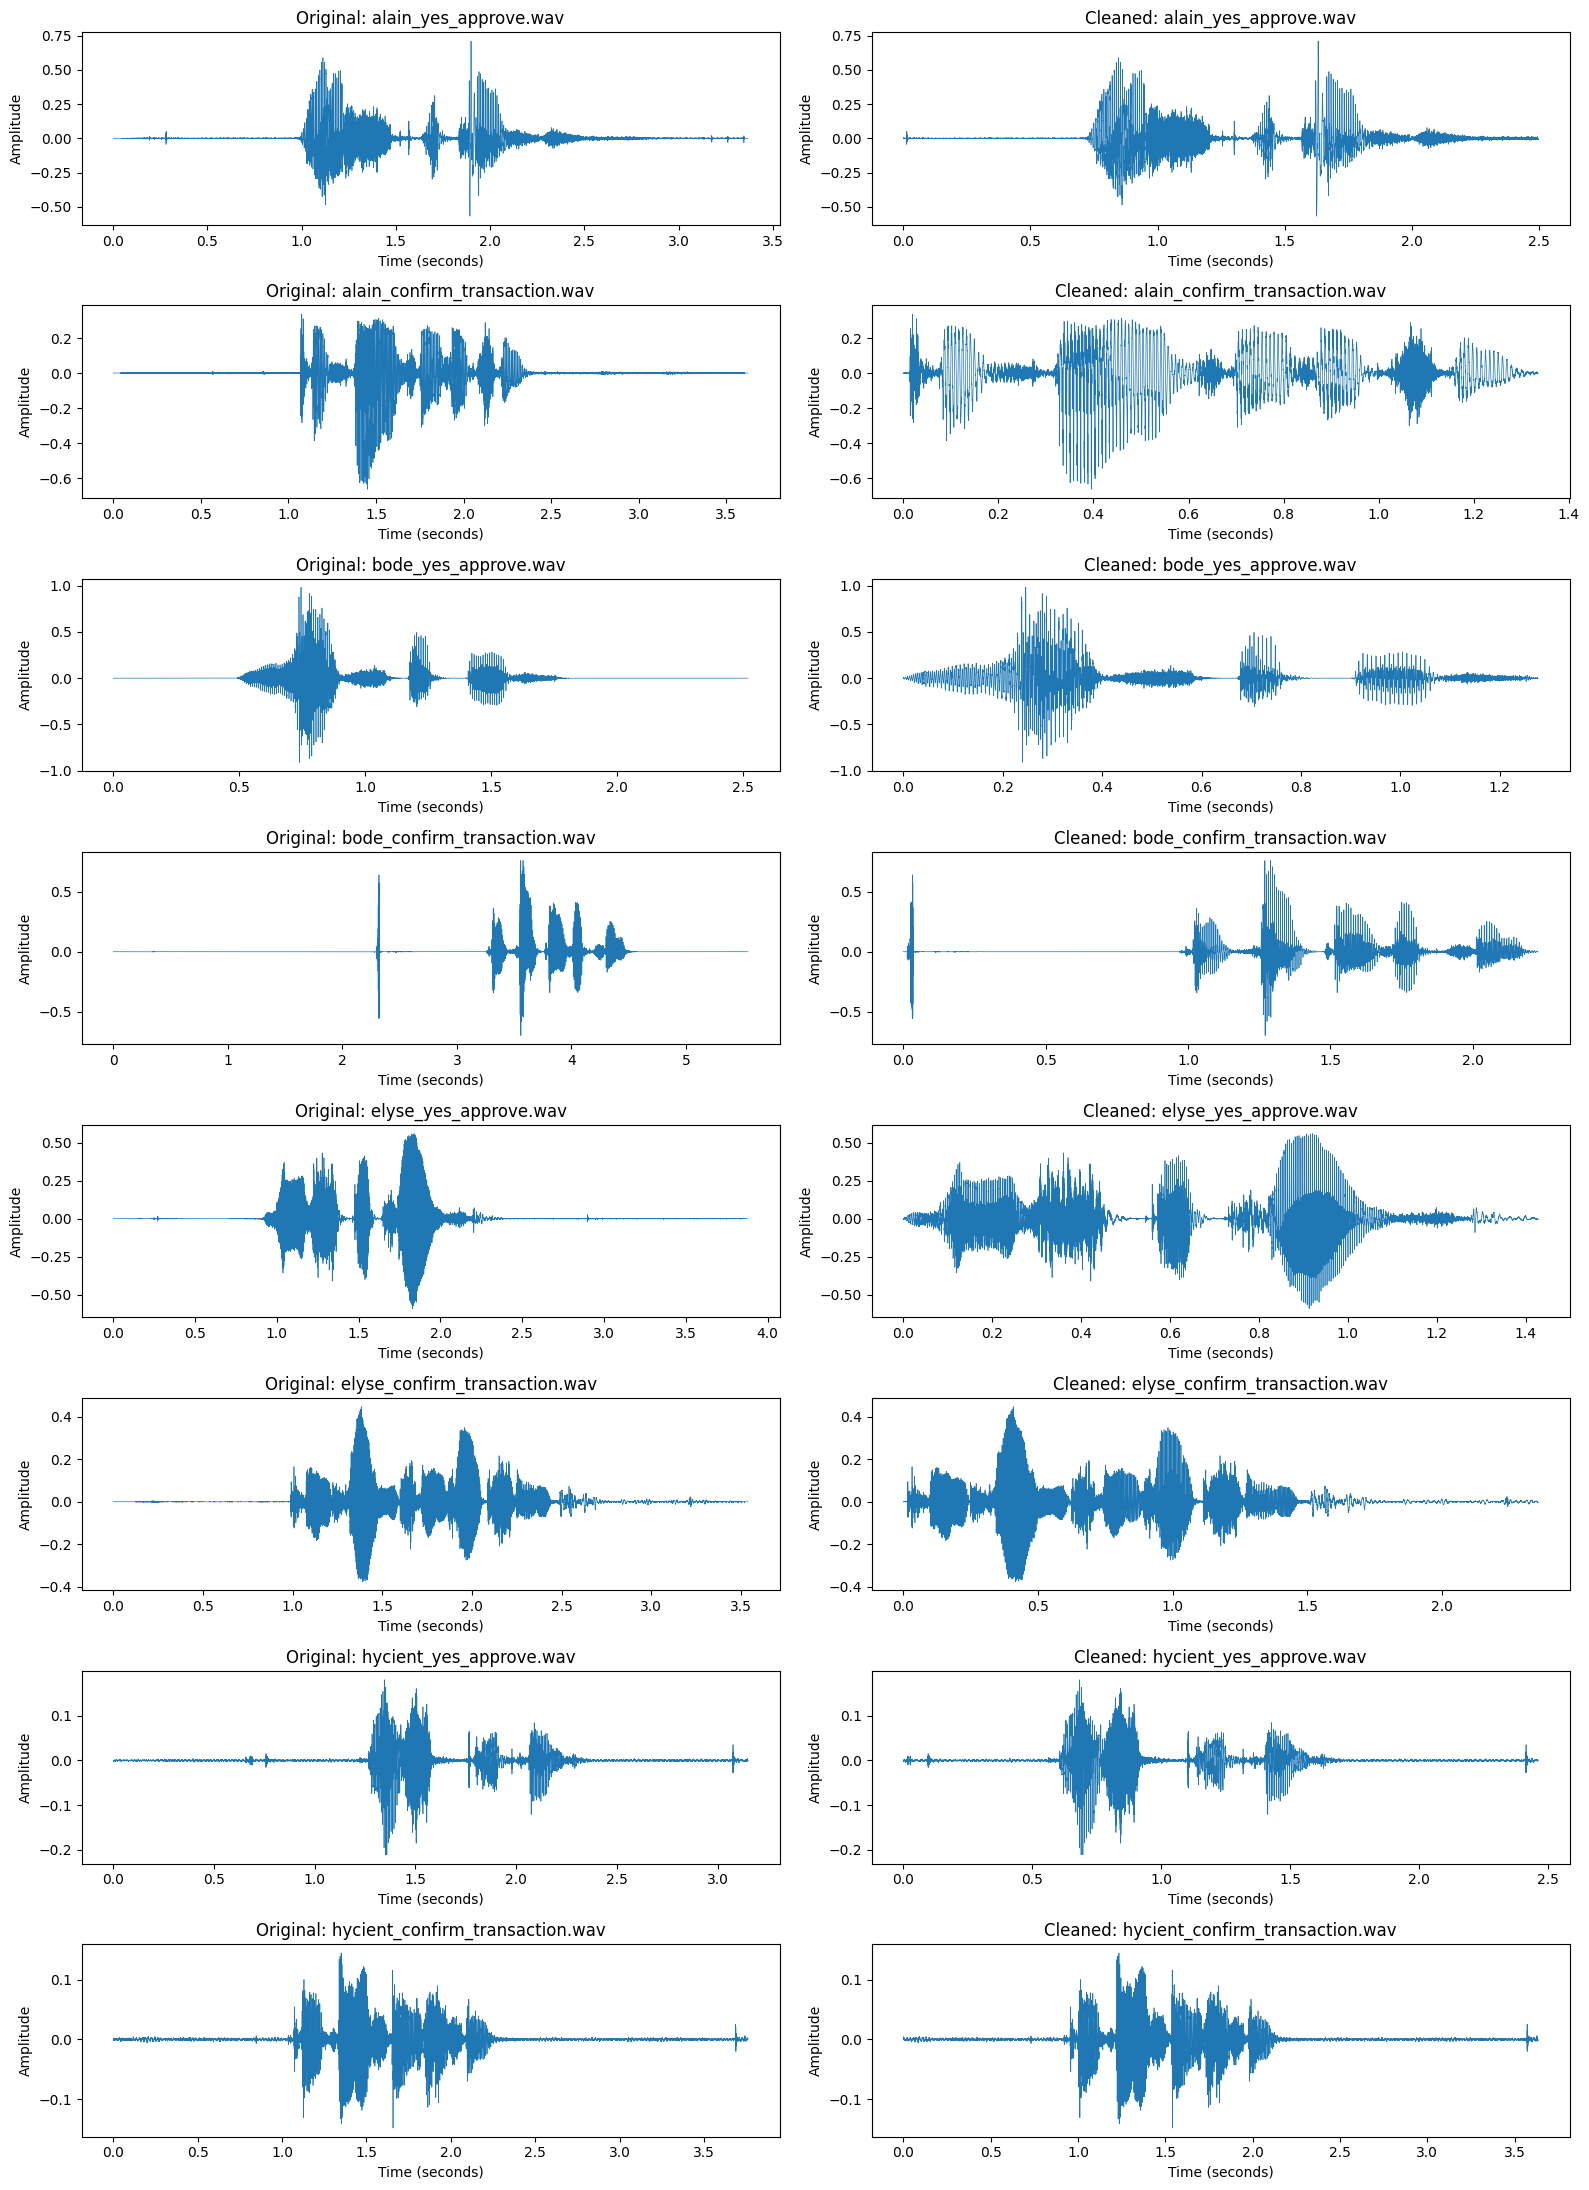

In [14]:
fig, axes = plt.subplots(8, 2, figsize=(16, 22))

for i, (filename, original_data) in enumerate(audio_data.items()):

    original = original_data["signal"]
    sr = original_data["sample_rate"]

    cleaned = cleaned_audio_data[filename]["signal"]

    original_time = np.arange(len(original)) / sr
    cleaned_time = np.arange(len(cleaned)) / sr

    axes[i, 0].plot(original_time, original, linewidth=0.5)
    axes[i, 0].set_title(f"Original: {filename}")
    axes[i, 0].set_xlabel("Time (seconds)")
    axes[i, 0].set_ylabel("Amplitude")

    axes[i, 1].plot(cleaned_time, cleaned, linewidth=0.5)
    axes[i, 1].set_title(f"Cleaned: {filename}")
    axes[i, 1].set_xlabel("Time (seconds)")
    axes[i, 1].set_ylabel("Amplitude")

plt.tight_layout()
plt.show()

## 5.7 Correction of Audio Trimming

Three recordings require manual boundary corrections because automatic silence detection did not identify their speech boundaries accurately.

The remaining five cleaned recordings are retained. The corrected recordings are created from the original WAV files and saved separately.

In [15]:
# Create a separate folder for the final cleaned recordings
FINAL_CLEANED_DIR = AUDIO_DIR.parent / "Cleaned_Audio_Final"
FINAL_CLEANED_DIR.mkdir(parents=True, exist_ok=True)

# Manually verified boundaries (seconds)
manual_boundaries = {
    "bode_confirm_transaction.wav": (3.25, 4.60),
    "hycient_yes_approve.wav": (1.20, 2.30),
    "hycient_confirm_transaction.wav": (1.00, 2.30)
}

final_cleaned_data = {}

for filename, data in audio_data.items():

    original_signal = data["signal"]
    sample_rate = data["sample_rate"]

    if filename in manual_boundaries:

        start_time, end_time = manual_boundaries[filename]

        start_sample = int(start_time * sample_rate)
        end_sample = int(end_time * sample_rate)

        final_signal = original_signal[start_sample:end_sample]

        print(f"Manually corrected: {filename}")

    else:
        # Retain the previously cleaned version
        final_signal = cleaned_audio_data[filename]["signal"]

        print(f"Retained existing cleaned version: {filename}")

    # Save into the new final folder
    output_path = FINAL_CLEANED_DIR / filename

    sf.write(output_path, final_signal, sample_rate)

    final_cleaned_data[filename] = {
        "signal": final_signal,
        "sample_rate": sample_rate,
        "duration": len(final_signal) / sample_rate
    }

print("\nFinal cleaned recordings saved in:")
print(FINAL_CLEANED_DIR)

Retained existing cleaned version: alain_yes_approve.wav
Retained existing cleaned version: alain_confirm_transaction.wav
Retained existing cleaned version: bode_yes_approve.wav
Manually corrected: bode_confirm_transaction.wav
Retained existing cleaned version: elyse_yes_approve.wav
Retained existing cleaned version: elyse_confirm_transaction.wav
Manually corrected: hycient_yes_approve.wav
Manually corrected: hycient_confirm_transaction.wav

Final cleaned recordings saved in:
/content/drive/MyDrive/Multimodal-Data-Preprocessing/Voice_Recognition/Cleaned_Audio_Final


## 5.8 Final Cleaned Audio Verification

The final cleaned recordings are checked for file availability, readability, sampling rate and duration.

In [16]:
final_verification = []

for filepath in sorted(FINAL_CLEANED_DIR.glob("*.wav")):

    signal, sample_rate = sf.read(filepath)

    final_verification.append({
        "Filename": filepath.name,
        "Sample Rate (Hz)": sample_rate,
        "Duration (seconds)": round(len(signal) / sample_rate, 2),
        "Readable": True
    })

final_verification_df = pd.DataFrame(final_verification)

display(final_verification_df)

assert len(final_verification_df) == 8
assert final_verification_df["Readable"].all()
assert (final_verification_df["Sample Rate (Hz)"] == 44100).all()

print("All 8 final cleaned recordings verified successfully.")

,Filename,Sample Rate (Hz),Duration (seconds),Readable
0,alain_confirm_transaction.wav,44100,1.34,True
1,alain_yes_approve.wav,44100,2.50,True
2,bode_confirm_transaction.wav,44100,1.35,True
3,bode_yes_approve.wav,44100,1.28,True
4,elyse_confirm_transaction.wav,44100,2.36,True
5,elyse_yes_approve.wav,44100,1.43,True
6,hycient_confirm_transaction.wav,44100,1.30,True
7,hycient_yes_approve.wav,44100,1.10,True


All 8 final cleaned recordings verified successfully.


# 6. Audio Data Augmentation

Audio augmentation increases the diversity of the dataset by creating modified versions of the cleaned recordings.

Two augmentation techniques are applied:

- Pitch shifting: Changes the pitch by two semitones while preserving the recording duration.
- Time stretching: Slows the recording slightly while preserving its original pitch.

Both techniques are applied to every cleaned recording, producing two augmented samples per recording.

The augmented recordings are stored separately from the original and cleaned datasets.

In [17]:
# Create a separate folder for final augmented recordings
AUGMENTED_FINAL_DIR = AUDIO_DIR.parent / "Augmented_Audio_Final"
AUGMENTED_FINAL_DIR.mkdir(parents=True, exist_ok=True)

augmentation_summary = []
augmented_audio_data = {}

for filename, data in final_cleaned_data.items():

    signal = data["signal"]
    sample_rate = data["sample_rate"]

    file_stem = Path(filename).stem

    # 1. Pitch shifting: increase pitch by two semitones
    pitch_shifted = librosa.effects.pitch_shift(
        y=signal,
        sr=sample_rate,
        n_steps=2
    )

    pitch_filename = f"{file_stem}_pitch_shift.wav"
    pitch_path = AUGMENTED_FINAL_DIR / pitch_filename

    sf.write(pitch_path, pitch_shifted, sample_rate)

    augmented_audio_data[pitch_filename] = {
        "signal": pitch_shifted,
        "sample_rate": sample_rate,
        "speaker": file_stem.split("_")[0],
        "augmentation": "Pitch shifting",
        "source_file": filename
    }

    augmentation_summary.append({
        "Original File": filename,
        "Augmentation": "Pitch shifting",
        "Augmented File": pitch_filename,
        "Duration (seconds)": round(
            len(pitch_shifted) / sample_rate, 2
        )
    })

    # 2. Time stretching: slow audio slightly
    time_stretched = librosa.effects.time_stretch(
        y=signal,
        rate=0.9
    )

    stretch_filename = f"{file_stem}_time_stretch.wav"
    stretch_path = AUGMENTED_FINAL_DIR / stretch_filename

    sf.write(stretch_path, time_stretched, sample_rate)

    augmented_audio_data[stretch_filename] = {
        "signal": time_stretched,
        "sample_rate": sample_rate,
        "speaker": file_stem.split("_")[0],
        "augmentation": "Time stretching",
        "source_file": filename
    }

    augmentation_summary.append({
        "Original File": filename,
        "Augmentation": "Time stretching",
        "Augmented File": stretch_filename,
        "Duration (seconds)": round(
            len(time_stretched) / sample_rate, 2
        )
    })

augmentation_df = pd.DataFrame(augmentation_summary)

display(augmentation_df)

print("Original cleaned recordings:", len(final_cleaned_data))
print("Augmented recordings created:", len(augmented_audio_data))
print("Saved in:", AUGMENTED_FINAL_DIR)

,Original File,Augmentation,Augmented File,Duration (seconds)
0,alain_yes_approve.wav,Pitch shifting,alain_yes_approve_pitch_shift.wav,2.50
1,alain_yes_approve.wav,Time stretching,alain_yes_approve_time_stretch.wav,2.77
2,alain_confirm_transaction.wav,Pitch shifting,alain_confirm_transaction_pitch_shift.wav,1.34
3,alain_confirm_transaction.wav,Time stretching,alain_confirm_transaction_time_stretch.wav,1.48
4,bode_yes_approve.wav,Pitch shifting,bode_yes_approve_pitch_shift.wav,1.28
5,bode_yes_approve.wav,Time stretching,bode_yes_approve_time_stretch.wav,1.42
6,bode_confirm_transaction.wav,Pitch shifting,bode_confirm_transaction_pitch_shift.wav,1.35
7,bode_confirm_transaction.wav,Time stretching,bode_confirm_transaction_time_stretch.wav,1.50
8,elyse_yes_approve.wav,Pitch shifting,elyse_yes_approve_pitch_shift.wav,1.43
9,elyse_yes_approve.wav,Time stretching,elyse_yes_approve_time_stretch.wav,1.59


Original cleaned recordings: 8
Augmented recordings created: 16
Saved in: /content/drive/MyDrive/Multimodal-Data-Preprocessing/Voice_Recognition/Augmented_Audio_Final


## 6.2 Augmented Audio Verification

The augmented recordings are checked to confirm that all expected files were saved successfully and retain the required sampling rate.

In [18]:
augmented_files = sorted(AUGMENTED_FINAL_DIR.glob("*.wav"))

augmentation_verification = []

for filepath in augmented_files:

    signal, sample_rate = sf.read(filepath)

    augmentation_verification.append({
        "Filename": filepath.name,
        "Sample Rate (Hz)": sample_rate,
        "Duration (seconds)": round(
            len(signal) / sample_rate, 2
        ),
        "Readable": True
    })

augmentation_verification_df = pd.DataFrame(
    augmentation_verification
)

display(augmentation_verification_df)

assert len(augmented_files) == 16
assert all(row["Sample Rate (Hz)"] == 44100
           for row in augmentation_verification)
assert all(row["Readable"]
           for row in augmentation_verification)

print("All 16 augmented recordings verified successfully.")

,Filename,Sample Rate (Hz),Duration (seconds),Readable
0,alain_confirm_transaction_pitch_shift.wav,44100,1.34,True
1,alain_confirm_transaction_time_stretch.wav,44100,1.48,True
2,alain_yes_approve_pitch_shift.wav,44100,2.50,True
3,alain_yes_approve_time_stretch.wav,44100,2.77,True
4,bode_confirm_transaction_pitch_shift.wav,44100,1.35,True
5,bode_confirm_transaction_time_stretch.wav,44100,1.50,True
6,bode_yes_approve_pitch_shift.wav,44100,1.28,True
7,bode_yes_approve_time_stretch.wav,44100,1.42,True
8,elyse_confirm_transaction_pitch_shift.wav,44100,2.36,True
9,elyse_confirm_transaction_time_stretch.wav,44100,2.62,True


All 16 augmented recordings verified successfully.


# 7. Audio Feature Extraction

Audio feature extraction converts the cleaned and augmented recordings into numerical representations for machine learning.

The following features are extracted:

- MFCC: Represents the spectral characteristics of speech.
- Spectral roll-off: Describes the distribution of frequency energy.
- RMS energy: Measures the signal's energy.

The mean and standard deviation of the MFCC coefficients, spectral roll-off and RMS energy are calculated for each recording.

The extracted features are associated with speaker identities, spoken phrases and source recordings.

In [19]:
import librosa
import numpy as np
import pandas as pd
from pathlib import Path

feature_records = []

# Combine cleaned and augmented recordings
all_audio_samples = {}

for filename, data in final_cleaned_data.items():
    all_audio_samples[filename] = {
        **data,
        "sample_type": "cleaned",
        "source_file": filename
    }

for filename, data in augmented_audio_data.items():
    all_audio_samples[filename] = {
        **data,
        "sample_type": "augmented",
        "source_file": data["source_file"]
    }

# Extract features from every recording
for filename, data in all_audio_samples.items():

    signal = data["signal"]
    sample_rate = data["sample_rate"]

    # MFCC features
    mfcc = librosa.feature.mfcc(
        y=signal,
        sr=sample_rate,
        n_mfcc=13
    )

    # Spectral roll-off
    rolloff = librosa.feature.spectral_rolloff(
        y=signal,
        sr=sample_rate
    )

    # RMS energy
    rms = librosa.feature.rms(
        y=signal
    )

    # Extract speaker and phrase labels
    original_name = data["source_file"]

    speaker = original_name.split("_")[0]
    phrase = original_name.replace(".wav", "")
    phrase = phrase[len(speaker) + 1:]

    # Store metadata and statistical features
    record = {
        "Filename": filename,
        "Speaker": speaker,
        "Phrase": phrase,
        "Sample Type": data["sample_type"],
        "Source File": original_name
    }

    # Mean and standard deviation of 13 MFCC coefficients
    for i in range(13):
        record[f"MFCC_{i+1}_Mean"] = float(np.mean(mfcc[i]))
        record[f"MFCC_{i+1}_Std"] = float(np.std(mfcc[i]))

    record["Spectral_Rolloff_Mean"] = float(np.mean(rolloff))
    record["Spectral_Rolloff_Std"] = float(np.std(rolloff))

    record["RMS_Energy_Mean"] = float(np.mean(rms))
    record["RMS_Energy_Std"] = float(np.std(rms))

    feature_records.append(record)

audio_features_df = pd.DataFrame(feature_records)

print("Total samples processed:", len(audio_features_df))
print("Total extracted features:", len(audio_features_df.columns) - 5)

display(audio_features_df.head())

Total samples processed: 24
Total extracted features: 30


,Filename,Speaker,Phrase,Sample Type,Source File,MFCC_1_Mean,MFCC_1_Std,MFCC_2_Mean,MFCC_2_Std,MFCC_3_Mean,...,MFCC_11_Mean,MFCC_11_Std,MFCC_12_Mean,MFCC_12_Std,MFCC_13_Mean,MFCC_13_Std,Spectral_Rolloff_Mean,Spectral_Rolloff_Std,RMS_Energy_Mean,RMS_Energy_Std
0,alain_yes_approve.wav,alain,yes_approve,cleaned,alain_yes_approve.wav,-344.149597,113.727036,96.093620,47.443245,-4.311244,...,-3.642570,6.976283,-5.631316,6.025703,-7.510394,10.053748,6901.590983,3149.876574,0.044120,0.063523
1,alain_confirm_transaction.wav,alain,confirm_transaction,cleaned,alain_confirm_transaction.wav,-273.128632,67.887749,143.241959,47.551281,-7.408587,...,-2.822870,9.053427,-2.355707,7.793979,-4.592779,11.138960,4415.977320,3787.026755,0.094893,0.065997
2,bode_yes_approve.wav,bode,yes_approve,cleaned,bode_yes_approve.wav,-309.253845,99.423973,99.826622,69.842941,13.942780,...,-1.883618,6.803610,-10.020094,6.376417,-9.478615,10.856673,5628.313714,4606.961362,0.081572,0.093908
3,bode_confirm_transaction.wav,bode,confirm_transaction,cleaned,bode_confirm_transaction.wav,-361.085663,106.249428,128.338760,57.349613,30.791275,...,-10.833849,11.245077,-10.045004,9.633507,-2.038455,9.170379,4191.060697,4080.731348,0.062122,0.055349
4,elyse_yes_approve.wav,elyse,yes_approve,cleaned,elyse_yes_approve.wav,-272.144135,113.875999,90.248688,41.557053,2.402828,...,-1.818054,12.249275,-2.635933,18.045856,3.325497,7.617696,7881.846963,2927.550067,0.081557,0.073114


## 7.2 Extracted Feature Inspection

The extracted feature dataset is examined to verify its dimensions, speaker distribution, sample types and missing values.

In [20]:
print("Dataset shape:", audio_features_df.shape)

print("\nSamples per speaker:")
display(audio_features_df["Speaker"].value_counts())

print("\nSamples by type:")
display(audio_features_df["Sample Type"].value_counts())

print("\nMissing values:")
print(audio_features_df.isnull().sum().sum())

print("\nFeature data types:")
display(audio_features_df.dtypes.value_counts())

Dataset shape: (24, 35)

Samples per speaker:


,count
Speaker,
alain,6
bode,6
elyse,6
hycient,6



Samples by type:


,count
Sample Type,
augmented,16
cleaned,8



Missing values:
0

Feature data types:


,count
float64,30
object,5


## 7.3 Export Audio Features

The extracted audio features are exported into a CSV file for subsequent model development and evaluation.

The dataset includes speaker labels, phrase information, sample types and numerical audio features.

In [21]:
# Export the extracted features to Google Drive
FEATURES_CSV_PATH = FEATURES_DIR / "audio_features.csv"

audio_features_df.to_csv(
    FEATURES_CSV_PATH,
    index=False
)

print("Audio features exported successfully.")
print("Saved at:", FEATURES_CSV_PATH)

Audio features exported successfully.
Saved at: /content/drive/MyDrive/Multimodal-Data-Preprocessing/Voice_Recognition/Features/audio_features.csv


## 7.4 Exported Dataset Verification

The exported CSV file is reloaded to confirm that its contents, dimensions and values match the extracted feature dataset.## 7.4 Exported Dataset Verification

The exported CSV file is reloaded to confirm that its contents, dimensions and values match the extracted feature dataset.

In [22]:
# Reload the exported CSV
verified_features_df = pd.read_csv(FEATURES_CSV_PATH)

print("Exported dataset shape:", verified_features_df.shape)
print("Missing values:", verified_features_df.isnull().sum().sum())

assert verified_features_df.shape == audio_features_df.shape
assert verified_features_df.isnull().sum().sum() == 0

print("\nSpeaker distribution:")
display(verified_features_df["Speaker"].value_counts())

print("\nSample type distribution:")
display(verified_features_df["Sample Type"].value_counts())

print("\nCSV verification successful.")

Exported dataset shape: (24, 35)
Missing values: 0

Speaker distribution:


,count
Speaker,
alain,6
bode,6
elyse,6
hycient,6



Sample type distribution:


,count
Sample Type,
augmented,16
cleaned,8



CSV verification successful.


# 8. Dataset Preparation for Voice Verification

Before developing the voice verification model, the extracted feature dataset is organized and checked.

This stage verifies speaker labels, recording sources and sample distribution. Original recordings and their augmented versions are treated as related samples to prevent data leakage during model evaluation.

The dataset will be organized into enrollment and verification samples using the two available spoken phrases.

In [23]:
# Load the verified feature dataset
model_data = pd.read_csv(FEATURES_CSV_PATH)

# Check the original recording groups
source_summary = (
    model_data.groupby(["Speaker", "Source File"])
    .agg(
        Total_Samples=("Filename", "count"),
        Sample_Types=("Sample Type", "nunique")
    )
    .reset_index()
)

print("Original recording groups:")
display(source_summary)

print("\nUnique speakers:", model_data["Speaker"].nunique())
print("Unique original recordings:", model_data["Source File"].nunique())
print("Total feature records:", len(model_data))

assert model_data["Speaker"].nunique() == 4
assert model_data["Source File"].nunique() == 8
assert len(model_data) == 24

print("\nDataset preparation checks passed.")

Original recording groups:


,Speaker,Source File,Total_Samples,Sample_Types
0,alain,alain_confirm_transaction.wav,3,2
1,alain,alain_yes_approve.wav,3,2
2,bode,bode_confirm_transaction.wav,3,2
3,bode,bode_yes_approve.wav,3,2
4,elyse,elyse_confirm_transaction.wav,3,2
5,elyse,elyse_yes_approve.wav,3,2
6,hycient,hycient_confirm_transaction.wav,3,2
7,hycient,hycient_yes_approve.wav,3,2



Unique speakers: 4
Unique original recordings: 8
Total feature records: 24

Dataset preparation checks passed.


## 8.2 Enrollment and Verification Data Organization

The recordings are separated by spoken phrase.

The "yes_approve" recordings are used to establish speaker enrollment profiles, while "confirm_transaction" recordings are reserved for verification.

Augmented samples remain grouped with their corresponding original recordings. This prevents augmented copies from leaking into the opposite evaluation group.

In [24]:
# Assign each recording to an enrollment or verification group
model_data["Dataset_Role"] = model_data["Phrase"].map({
    "yes_approve": "enrollment",
    "confirm_transaction": "verification"
})

print("Samples by dataset role:")
display(model_data["Dataset_Role"].value_counts())

print("\nSpeaker distribution by role:")
display(
    model_data.groupby(["Speaker", "Dataset_Role"])
    .size()
    .unstack(fill_value=0)
)

assert model_data["Dataset_Role"].notna().all()

print("\nEnrollment and verification groups created successfully.")

Samples by dataset role:


,count
Dataset_Role,
enrollment,12
verification,12



Speaker distribution by role:


Dataset_Role,enrollment,verification
Speaker,,
alain,3,3
bode,3,3
elyse,3,3
hycient,3,3



Enrollment and verification groups created successfully.


# 9. Voice Verification Model

A machine learning model is developed to identify speakers from their extracted audio features. The enrollment recordings are used for training, while the separate verification recordings are used for testing.

VOICE MODEL EVALUATION
----------------------
Training samples: 12
Testing samples: 12
Accuracy: 91.67%
Weighted F1-score: 91.43%

Classification Report:
              precision    recall  f1-score   support

       alain       1.00      0.67      0.80         3
        bode       0.75      1.00      0.86         3
       elyse       1.00      1.00      1.00         3
     hycient       1.00      1.00      1.00         3

    accuracy                           0.92        12
   macro avg       0.94      0.92      0.91        12
weighted avg       0.94      0.92      0.91        12



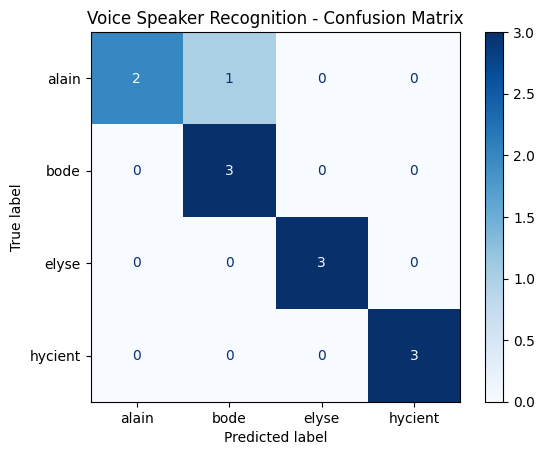

In [25]:
# Prepare enrollment data for training and verification data for testing

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

feature_columns = [
    col for col in model_data.select_dtypes(include=[np.number]).columns
    if col != "Dataset_Role"
]

train_data = model_data[model_data["Dataset_Role"] == "enrollment"]
test_data = model_data[model_data["Dataset_Role"] == "verification"]

X_train = train_data[feature_columns]
y_train = train_data["Speaker"]

X_test = test_data[feature_columns]
y_test = test_data["Speaker"]

# Build and train the speaker recognition model
voice_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(kernel="linear", class_weight="balanced"))
])

voice_model.fit(X_train, y_train)

# Predict speakers in the verification dataset
y_pred = voice_model.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average="weighted")

print("VOICE MODEL EVALUATION")
print("----------------------")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print(f"Accuracy: {accuracy:.2%}")
print(f"Weighted F1-score: {f1:.2%}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Display confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=sorted(y_train.unique()),
    cmap="Blues"
)
plt.title("Voice Speaker Recognition - Confusion Matrix")
plt.show()

### 9.1 Model Evaluation Results

The Support Vector Machine (SVM) model achieved an accuracy of 91.67% and a weighted F1-score of 91.43% on the verification dataset.

Out of 12 verification samples, 11 were correctly classified.

- Alain: 2 out of 3 correctly classified.
- Bode: 3 out of 3 correctly classified.
- Elyse: 3 out of 3 correctly classified.
- Hycient: 3 out of 3 correctly classified.

The model demonstrated promising initial speaker recognition results. However, the dataset is small, and augmented recordings are derived from the same original recordings. Therefore, these results should be interpreted as an initial experiment rather than a reliable measure of real-world voice recognition performance.

### 9.2 Model Loss and Evaluation Notes

The voice verification model uses a Support Vector Machine (SVM) classifier.

Unlike neural network models, the SVM implementation used in this project does not provide an epoch-based training loss history. Therefore, loss is not reported as a separate evaluation metric.

Model performance is evaluated using accuracy, weighted F1-score, the classification report and the confusion matrix.

The model achieved 91.67% accuracy and a weighted F1-score of 91.43% on the verification dataset. These results are preliminary because the dataset contains a limited number of original recordings and augmented samples derived from those recordings.

# 10. Voice Authentication Demonstration

This section demonstrates how the voice verification system checks whether a submitted voice matches the claimed speaker identity.

Two scenarios are tested:
1. Authorized attempt: the claimed identity matches the recognized speaker.
2. Unauthorized attempt: the claimed identity does not match the recognized speaker.

The demonstration uses existing recordings from the four group members.

In [26]:
# Voice authentication function

def verify_voice(audio_features, claimed_identity):
    predicted_identity = voice_model.predict(audio_features)[0]

    if predicted_identity == claimed_identity:
        status = "ACCESS GRANTED"
    else:
        status = "ACCESS DENIED"

    return predicted_identity, status


# Select a correctly classified verification recording
correct_indices = np.where(y_test.to_numpy() == y_pred)[0]
sample_index = correct_indices[0]

sample_features = X_test.iloc[[sample_index]]
actual_speaker = y_test.iloc[sample_index]

# Scenario 1: Authorized attempt
authorized_claim = actual_speaker
authorized_prediction, authorized_status = verify_voice(
    sample_features, authorized_claim
)

print("AUTHORIZED ATTEMPT")
print("------------------")
print("Claimed identity:", authorized_claim)
print("Recognized identity:", authorized_prediction)
print("Result:", authorized_status)


# Scenario 2: Unauthorized identity mismatch
unauthorized_claim = next(
    speaker for speaker in sorted(y_train.unique())
    if speaker != actual_speaker
)

unauthorized_prediction, unauthorized_status = verify_voice(
    sample_features, unauthorized_claim
)

print("\nUNAUTHORIZED ATTEMPT")
print("--------------------")
print("Claimed identity:", unauthorized_claim)
print("Recognized identity:", unauthorized_prediction)
print("Result:", unauthorized_status)

AUTHORIZED ATTEMPT
------------------
Claimed identity: bode
Recognized identity: bode
Result: ACCESS GRANTED

UNAUTHORIZED ATTEMPT
--------------------
Claimed identity: alain
Recognized identity: bode
Result: ACCESS DENIED


## 10.1 Authentication Test Results

The voice authentication system was tested using two scenarios:

**Authorized attempt:** The recording belonged to Bode, and the claimed identity was also Bode. The system recognized the speaker correctly and granted access.

**Unauthorized attempt:** The same Bode recording was submitted with Alain as the claimed identity. The system recognized Bode, detected the identity mismatch and denied access.

Both scenarios produced the expected results. This demonstrates the identity-matching mechanism using recordings from the group members.

In [27]:
import joblib

# Save the trained voice recognition model
MODEL_PATH = MODELS_DIR / "voice_verification_model.joblib"

joblib.dump(voice_model, MODEL_PATH)

# Verify that the model was saved
assert MODEL_PATH.exists()

print("Voice model saved successfully:")
print(MODEL_PATH)

Voice model saved successfully:
/content/drive/MyDrive/Multimodal-Data-Preprocessing/Voice_Recognition/Models/voice_verification_model.joblib


In [28]:
script_path = MODELS_DIR / "voice_verification.py"

script_code = '''
import joblib
import numpy as np

class VoiceVerification:
    def __init__(self, model_path):
        self.model = joblib.load(model_path)

    def predict_speaker(self, features):
        return self.model.predict(features)[0]

    def verify(self, features, claimed_identity):
        predicted_identity = self.predict_speaker(features)

        return {
            "claimed_identity": claimed_identity,
            "predicted_identity": predicted_identity,
            "verified": predicted_identity == claimed_identity
        }
'''

with open(script_path, "w") as file:
    file.write(script_code)

print("Python script created:", script_path)
print("File exists:", script_path.exists())

Python script created: /content/drive/MyDrive/Multimodal-Data-Preprocessing/Voice_Recognition/Models/voice_verification.py
File exists: True


In [29]:
print("Number of model features:", len(feature_columns))
print(feature_columns)

Number of model features: 30
['MFCC_1_Mean', 'MFCC_1_Std', 'MFCC_2_Mean', 'MFCC_2_Std', 'MFCC_3_Mean', 'MFCC_3_Std', 'MFCC_4_Mean', 'MFCC_4_Std', 'MFCC_5_Mean', 'MFCC_5_Std', 'MFCC_6_Mean', 'MFCC_6_Std', 'MFCC_7_Mean', 'MFCC_7_Std', 'MFCC_8_Mean', 'MFCC_8_Std', 'MFCC_9_Mean', 'MFCC_9_Std', 'MFCC_10_Mean', 'MFCC_10_Std', 'MFCC_11_Mean', 'MFCC_11_Std', 'MFCC_12_Mean', 'MFCC_12_Std', 'MFCC_13_Mean', 'MFCC_13_Std', 'Spectral_Rolloff_Mean', 'Spectral_Rolloff_Std', 'RMS_Energy_Mean', 'RMS_Energy_Std']


In [30]:
# Verify the main voice recognition deliverables

required_files = {
    "Audio features CSV": FEATURES_CSV_PATH,
    "Trained voice model": MODEL_PATH,
    "Voice verification Python script": script_path
}

print("VOICE RECOGNITION DELIVERABLES")
print("=" * 45)

for name, path in required_files.items():
    status = "FOUND" if path.exists() else "MISSING"
    print(f"{name}: {status}")
    print(f"Location: {path}\n")

all_found = all(path.exists() for path in required_files.values())

print("=" * 45)
print("All three files verified:", all_found)

VOICE RECOGNITION DELIVERABLES
Audio features CSV: FOUND
Location: /content/drive/MyDrive/Multimodal-Data-Preprocessing/Voice_Recognition/Features/audio_features.csv

Trained voice model: FOUND
Location: /content/drive/MyDrive/Multimodal-Data-Preprocessing/Voice_Recognition/Models/voice_verification_model.joblib

Voice verification Python script: FOUND
Location: /content/drive/MyDrive/Multimodal-Data-Preprocessing/Voice_Recognition/Models/voice_verification.py

All three files verified: True


In [31]:
import importlib.util

spec = importlib.util.spec_from_file_location(
    "voice_verification",
    script_path
)

voice_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(voice_module)

print("Python script imported successfully.")
print("Available class:", hasattr(voice_module, "VoiceVerification"))

Python script imported successfully.
Available class: True


In [32]:
# Test the standalone voice verification script

script_verifier = voice_module.VoiceVerification(MODEL_PATH)

# Authorized test: correct claimed identity
authorized_script_result = script_verifier.verify(
    sample_features,
    actual_speaker
)

# Unauthorized test: deliberately incorrect claimed identity
wrong_identity = next(
    speaker for speaker in sorted(y_train.unique())
    if speaker != actual_speaker
)

unauthorized_script_result = script_verifier.verify(
    sample_features,
    wrong_identity
)

print("AUTHORIZED TEST")
print(authorized_script_result)

print("\nUNAUTHORIZED TEST")
print(unauthorized_script_result)

AUTHORIZED TEST
{'claimed_identity': 'bode', 'predicted_identity': 'bode', 'verified': True}

UNAUTHORIZED TEST
{'claimed_identity': 'alain', 'predicted_identity': 'bode', 'verified': False}


# 11. Voice Recognition Component Handover

## 11.1 Component Overview

The voice recognition component identifies a speaker using extracted audio features and a trained Support Vector Machine (SVM) classifier.

The component uses recordings from four group members: Alain, Bode, Elyse and Hycient.

## 11.2 Files Provided

The following files are provided for integration:

- `audio_features.csv`: Extracted MFCC, spectral roll-off and RMS energy features.
- `voice_verification_model.joblib`: Trained SVM model and preprocessing pipeline.
- `voice_verification.py`: Python script containing the voice verification class.
- `Voice_Recognition.ipynb`: Notebook documenting audio preprocessing, augmentation, feature extraction, model training and evaluation.

## 11.3 Verification Interface

The `VoiceVerification` class provides the following methods:

- `predict_speaker(features)`: Predicts the speaker identity from extracted numerical features.
- `verify(features, claimed_identity)`: Compares the predicted identity with the claimed identity and returns the verification result.

The input to these methods must be a feature DataFrame containing the same 30 features and column names used during model training.

## 11.4 Integration Output

The verification component returns:

- Claimed identity
- Predicted identity
- Verification result (`True` or `False`)

The integration system can use the verification result to determine whether voice authentication succeeds or fails.

## 11.5 Model Performance and Limitations

The model achieved 91.67% accuracy and a weighted F1-score of 91.43% on the verification dataset.

The dataset contains a limited number of original recordings. Augmented recordings are derived from the original samples, so the evaluation results should be treated as preliminary.

The current verification component compares a claimed identity against the predicted identity. It has not been validated for unknown-speaker detection.